# Question 1 — Logistic Regression from first principles

This notebook trains the central NumPy implementation in `src/q1_models.py`. It does not redefine or substitute the algorithm. Data generation, splitting, training, numerical checking and evaluation are separate executable steps. All labels and values below come from this execution.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
root = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (root / 'src').is_dir(), 'Run from the project root or notebooks directory'
sys.path.insert(0, str(root))
from src.q1_models import LogisticRegressionGD, gradient_check
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
%matplotlib inline

## Model and objective
For binary $y$, predict $p_i=\sigma(x_i^Tw+b)$. Bernoulli negative log-likelihood is $J=-\frac1m\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)]$. For one sample, $\partial\ell_i/\partial p_i=(p_i-y_i)/[p_i(1-p_i)]$, and $\partial p_i/\partial z_i=p_i(1-p_i)$, so $\partial\ell_i/\partial z_i=p_i-y_i$. Thus $\nabla_w J=X^T(p-y)/m$ and $\partial J/\partial b=\mathrm{mean}(p-y)$. Stable BCE uses `logaddexp(0,z)-y*z`.

## Inspect the actual shared implementation
The source below is the code used by both the experiment script and this notebook. No sklearn estimator trains this scratch model.

In [2]:
print(inspect.getsource(LogisticRegressionGD))

class LogisticRegressionGD:
    """Minimize stable binary cross entropy: mean(logaddexp(0,z)-y*z)."""

    def __init__(self, learning_rate=0.13, epochs=2400):
        self.learning_rate, self.epochs = learning_rate, epochs

    @staticmethod
    def sigmoid(z):
        z = np.asarray(z, float)
        out = np.empty_like(z)
        mask = z >= 0
        out[mask] = 1 / (1 + np.exp(-z[mask]))
        ez = np.exp(z[~mask])
        out[~mask] = ez / (1 + ez)
        return out

    def _loss_grad(self, X, y, w, b):
        z = X @ w + b
        p = self.sigmoid(z)
        residual = p - y
        loss = float(np.mean(np.logaddexp(0, z) - y * z))
        return loss, X.T @ residual / len(y), float(np.mean(residual))

    def fit(self, X, y):
        X, y = training_inputs(X, y, self.learning_rate, self.epochs)
        if not set(np.unique(y)).issubset({0.0, 1.0}):
            raise ValueError("Binary y values must be 0/1")
        self.weights_ = np.zeros(X.shape[1])
        self.bias_ = 

## Generate data and protect the test set
Scaling is fitted after splitting, using training features only. Synthetic Q1 datasets are permitted by the original assignment.

In [3]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=600, n_features=5, n_informative=4, n_redundant=0, weights=[.55,.45], class_sep=1.2, flip_y=.04, random_state=27)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)
print("Train/test:", X_train.shape, X_test.shape)
print("Train-fitted scaler mean:", scaler.mean_)

Train/test: (480, 5) (120, 5)
Train-fitted scaler mean: [ 0.00769805  0.1851193  -0.00324269  0.63518653  0.75589533]


## Perform full-batch Gradient Descent
Zero initialization is deterministic. Each update subtracts the gradient computed at the current weights and intercept. Loss history includes the initial parameters and the final update.

Initial/final objective: 0.6931471805599453 0.2346856322496315
Central finite difference max absolute error: 3.606420717616743e-11
Final gradient norm: 0.0003264776191688905


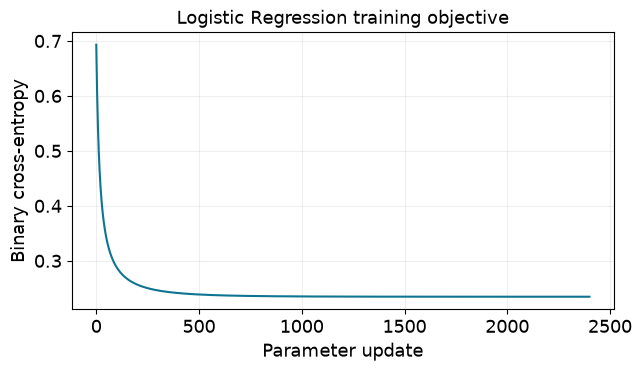

In [4]:
model = LogisticRegressionGD().fit(X_train, y_train)
error = gradient_check(LogisticRegressionGD(), X_train[:20], y_train[:20])
assert error < 1e-7
print("Initial/final objective:", model.loss_history_[0], model.loss_history_[-1])
print("Central finite difference max absolute error:", error)
print("Final gradient norm:", model.gradient_norm_)
plt.figure(figsize=(7, 3.6))
plt.plot(model.loss_history_, color="#0E7490")
plt.xlabel("Parameter update")
plt.ylabel("Binary cross-entropy")
plt.title("Logistic Regression training objective")
plt.grid(alpha=.2)
plt.show()

## Evaluate the fixed model on held-out data
Positive label is 1 and threshold is 0.5. Precision, recall and F1 use class 1; ROC-AUC uses continuous probabilities.

accuracy     0.883333
precision    0.833333
recall       0.925926
f1           0.877193
roc_auc      0.925084
Name: Test result, dtype: float64

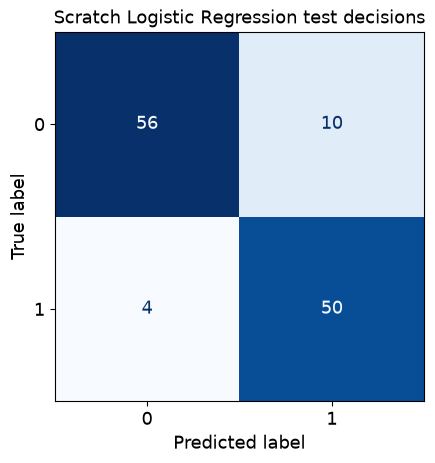

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
probs = model.predict_proba(X_test); pred = model.predict(X_test)
measured = dict(accuracy=accuracy_score(y_test,pred), precision=precision_score(y_test,pred), recall=recall_score(y_test,pred), f1=f1_score(y_test,pred), roc_auc=roc_auc_score(y_test,probs))
display(pd.Series(measured, name="Test result"))
ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap="Blues",colorbar=False)
plt.title("Scratch Logistic Regression test decisions");plt.show()

## Independent validation benchmark and stability
A separate unregularized sklearn LBFGS fit validates the objective; it is not used to train the scratch parameters. Finite iteration counts leave a measurable optimization difference.

In [6]:
from sklearn.linear_model import LogisticRegression
reference = LogisticRegression(C=np.inf, tol=1e-10, max_iter=10000).fit(X_train, y_train)
reference_loss = model._loss_grad(X_train, y_train, reference.coef_[0], reference.intercept_[0])[0]
max_difference = np.max(np.abs(reference.predict_proba(X_test)[:,1]-probs))
print("Scratch/reference training BCE:", model.loss_history_[-1], reference_loss)
print("Maximum probability difference:", max_difference)
assert abs(model.loss_history_[-1]-reference_loss) < 1e-5
assert max_difference < .005
with np.errstate(over="raise", invalid="raise", divide="raise"):
    display(model.sigmoid(np.array([-1000.,0.,1000.])))

Scratch/reference training BCE: 0.2346856322496315 0.23468148173309383
Maximum probability difference: 0.0019908022840458006


array([0. , 0.5, 1. ])

## Trace to the experiment and interpret
These assertions compare the independently executed notebook with the generated experiment JSON. They do not copy the reported scores into the notebook evaluation.

In [7]:
saved = json.loads((root / "results/q1_metrics.json").read_text())["logistic"]
for key, value in measured.items():
    assert np.isclose(value, saved[key], rtol=0, atol=1e-12), key
print("Notebook metrics agree with independently executed script.")

Notebook metrics agree with independently executed script.


The measured recall exceeds precision at threshold 0.5, indicating a false-alarm versus missed-positive trade-off. BCE and ROC-AUC do not by themselves establish probability calibration. The controlled synthetic result is not a deployment claim.